In [ ]:
import os
import gc
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

if not tf.config.list_physical_devices("GPU"):
    print(
        "⚠️ WARNING: no GPU detected. "
        "Set Runtime > Change runtime type > T4 GPU, "
        "then Runtime > Restart runtime."
    )

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

paths = [
    "/content/drive/MyDrive/cleaned_dataset.zip",
    "/content/drive/MyDrive/plant_disease_mobilenetv2_v3.keras",
    "/content/drive/MyDrive/model.keras",
    "/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage2.keras"
]

for path in paths:
    print(f"{path}: {os.path.exists(path)}")

/content/drive/MyDrive/cleaned_dataset.zip: True
/content/drive/MyDrive/plant_disease_mobilenetv2_v3.keras: True
/content/drive/MyDrive/model.keras: True
/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage2.keras: True


In [ ]:
import os

DATA_ZIP = "/content/drive/MyDrive/cleaned_dataset.zip"
data_dir = "/content/plant_data/cleaned_dataset"

os.makedirs("/content/plant_data", exist_ok=True)

if not os.path.exists(data_dir):
    !unzip -q "/content/drive/MyDrive/cleaned_dataset.zip" -d /content/plant_data

print("Dataset folder exists:", os.path.exists(data_dir))
print("Dataset folders:", len([
    name for name in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, name))
]))

Dataset folder exists: True
Dataset folders: 38


In [ ]:
!pip -q install split-folders

In [ ]:
import splitfolders
import os

splitfolders.ratio(
    "/content/plant_data/cleaned_dataset",
    output="/content/split_data",
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)

print("Training folder exists:",
      os.path.exists("/content/split_data/train"))

Copying files: 54284 files [00:35, 1540.62 files/s]

Training folder exists: True


In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/train",
    image_size=(224, 224),
    batch_size=32,
    label_mode="int"
)

class_names = train_ds_raw.class_names

print("Number of classes:", len(class_names))

for i, name in enumerate(class_names):
    print(f"{i}: {name}")

Found 37982 files belonging to 38 classes.
Number of classes: 38
0: Apple___Apple_scab
1: Apple___Black_rot
2: Apple___Cedar_apple_rust
3: Apple___healthy
4: Blueberry___healthy
5: Cherry_(including_sour)___Powdery_mildew
6: Cherry_(including_sour)___healthy
7: Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8: Corn_(maize)___Common_rust_
9: Corn_(maize)___Northern_Leaf_Blight
10: Corn_(maize)___healthy
11: Grape___Black_rot
12: Grape___Esca_(Black_Measles)
13: Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14: Grape___healthy
15: Orange___Haunglongbing_(Citrus_greening)
16: Peach___Bacterial_spot
17: Peach___healthy
18: Pepper,_bell___Bacterial_spot
19: Pepper,_bell___healthy
20: Potato___Early_blight
21: Potato___Late_blight
22: Potato___healthy
23: Raspberry___healthy
24: Soybean___healthy
25: Squash___Powdery_mildew
26: Strawberry___Leaf_scorch
27: Strawberry___healthy
28: Tomato___Bacterial_spot
29: Tomato___Early_blight
30: Tomato___Late_blight
31: Tomato___Leaf_Mold
32: Tomato___

In [ ]:
import json
import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

model_path = "/content/drive/MyDrive/plant_disease_mobilenetv2_v3.keras"

model = tf.keras.models.load_model(model_path)

classes = json.load(open(
    "/content/drive/MyDrive/model_class_names.json",
    encoding="utf-8"
)) if __import__("os").path.exists(
    "/content/drive/MyDrive/model_class_names.json"
) else class_names

image_path = (
    "/content/plant_data/cleaned_dataset/"
    "Tomato___Early_blight/"
    "0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG"
)

image = Image.open(image_path).convert("RGB").resize((224, 224))
pixels = np.array(image, dtype=np.float32)
pixels = preprocess_input(pixels)

scores = model.predict(np.expand_dims(pixels, axis=0), verbose=0)[0]

print("Expected class: Tomato___Early_blight")
print("Output size:", len(scores))
print("\nTop 5 predictions:")

for i in np.argsort(scores)[::-1][:5]:
    print(f"{classes[i]}: {scores[i] * 100:.2f}%")

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 114 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Expected class: Tomato___Early_blight
Output size: 38

Top 5 predictions:
Apple___Apple_scab: 75.40%
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 14.29%
Peach___Bacterial_spot: 6.98%
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 3.21%
Tomato___Bacterial_spot: 0.05%


In [ ]:

import numpy as np
import tensorflow as tf
from tensorflow.keras import layers
from PIL import Image

# Rebuild the same architecture used in Stage 2
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

checkpoint_model = tf.keras.Model(inputs, outputs)

# Load the saved Stage 2 weights (no training)
checkpoint_path = (
    "/content/drive/MyDrive/plant_checkpoints_v3/"
    "best_model_stage2.keras"
)
checkpoint_model.load_weights(checkpoint_path)
print("Stage 2 checkpoint weights loaded.")

# Test the same labelled image
image_path = (
    "/content/plant_data/cleaned_dataset/"
    "Tomato___Early_blight/"
    "0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG"
)

image = Image.open(image_path).convert("RGB").resize((224, 224))
pixels = np.array(image, dtype=np.float32)
pixels = tf.keras.applications.mobilenet_v2.preprocess_input(pixels)

scores = checkpoint_model.predict(
    np.expand_dims(pixels, axis=0), verbose=0
)[0]

print("Expected class: Tomato___Early_blight")
print("\nTop 5 checkpoint predictions:")

for i in np.argsort(scores)[::-1][:5]:
    print(f"{class_names[i]}: {scores[i] * 100:.2f}%")


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Stage 2 checkpoint weights loaded.
Expected class: Tomato___Early_blight

Top 5 checkpoint predictions:
Apple___Apple_scab: 75.40%
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 14.29%
Peach___Bacterial_spot: 6.98%
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot: 3.21%
Tomato___Bacterial_spot: 0.05%


In [ ]:
import os

metrics_path = "/content/drive/MyDrive/plant_disease_metrics_v3.json"
report_path = "/content/drive/MyDrive/plant_disease_evaluation_v3/classification_report_v3.txt"

for path in [metrics_path, report_path]:
    print(f"\n{'=' * 60}")
    print("File:", path)
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        with open(path, "r", encoding="utf-8") as f:
            print(f.read()[:12000])


File: /content/drive/MyDrive/plant_disease_metrics_v3.json
Exists: True
{
  "test_accuracy": 0.9763942956924438,
  "test_loss": 0.07301150262355804,
  "num_classes": 38,
  "test_samples": 8176
}

File: /content/drive/MyDrive/plant_disease_evaluation_v3/classification_report_v3.txt
Exists: True
                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.95      0.97        95
                                 Apple___Black_rot       1.00      1.00      1.00        94
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        42
                                   Apple___healthy       0.99      1.00      1.00       247
                               Blueberry___healthy       0.99      1.00      0.99       226
          Cherry_(including_sour)___Powdery_mildew       0.99      1.00      1.00       159
                 Cherry_(including_sour)___healthy       0.

In [ ]:
import os
import numpy as np
import tensorflow as tf
from PIL import Image

test_folder = "/content/split_data/test/Tomato___Early_blight"
model_path = "/content/drive/MyDrive/plant_disease_mobilenetv2_v3.keras"

if not os.path.isdir(test_folder):
    print("Test folder not found:", test_folder)
    print("Available split folders:")
    print(os.listdir("/content/split_data"))
else:
    model = tf.keras.models.load_model(model_path, compile=False)

    image_files = sorted([
        f for f in os.listdir(test_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])[:10]

    correct = 0

    for filename in image_files:
        path = os.path.join(test_folder, filename)

        image = Image.open(path).convert("RGB").resize((224, 224))
        pixels = np.array(image, dtype=np.float32)
        pixels = tf.keras.applications.mobilenet_v2.preprocess_input(pixels)

        scores = model.predict(
            np.expand_dims(pixels, axis=0), verbose=0
        )[0]

        predicted_index = int(np.argmax(scores))
        predicted_class = class_names[predicted_index]
        confidence = float(scores[predicted_index]) * 100

        is_correct = predicted_class == "Tomato___Early_blight"
        correct += int(is_correct)

        print(f"\nImage: {filename}")
        print(f"Prediction: {predicted_class}")
        print(f"Confidence: {confidence:.2f}%")
        print(f"Correct: {'Yes' if is_correct else 'No'}")

    if image_files:
        print(f"\nCorrect: {correct}/{len(image_files)}")
        print(f"Accuracy on these samples: {correct / len(image_files) * 100:.2f}%")


Image: 011aa278-a39e-40b0-b6e4-2e2f835889f0___RS_Erly.B 8251.JPG
Prediction: Tomato___Early_blight
Confidence: 100.00%
Correct: Yes

Image: 072ae43a-416b-434a-a5a2-1b48bc47fada___RS_Erly.B 7472.JPG
Prediction: Tomato___Early_blight
Confidence: 78.93%
Correct: Yes

Image: 07409e2c-a730-4b11-b25e-31025bd63a91___RS_Erly.B 9578.JPG
Prediction: Tomato___Early_blight
Confidence: 99.58%
Correct: Yes

Image: 079e0d43-e9d2-4217-b8e8-2f3b989cdab2___RS_Erly.B 7588.JPG
Prediction: Tomato___Early_blight
Confidence: 100.00%
Correct: Yes

Image: 089243e5-f319-4ed2-b10c-603328ff4143___RS_Erly.B 9428.JPG
Prediction: Tomato___Early_blight
Confidence: 99.25%
Correct: Yes

Image: 0c221e01-a85e-4794-b45b-3a91e349a8d2___RS_Erly.B 6425.JPG
Prediction: Tomato___Early_blight
Confidence: 99.95%
Correct: Yes

Image: 0cd17aff-13d8-439a-ac08-dae1aea55edb___RS_Erly.B 7828.JPG
Prediction: Tomato___Target_Spot
Confidence: 47.95%
Correct: No

Image: 0f03a09c-aa48-4d51-95e1-752c466c3742___RS_Erly.B 6413.JPG
Prediction

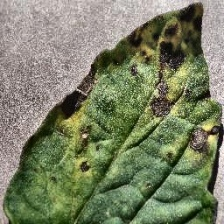

Expected label: Tomato___Early_blight

Top 3 predictions:
Apple___Apple_scab: 75.40%
Grape___Leaf_blight_(Isariopsis_Leaf_Spot): 14.29%
Peach___Bacterial_spot: 6.98%


In [ ]:
import numpy as np
import tensorflow as tf
from PIL import Image
import matplotlib.pyplot as plt

image_path = (
    "/content/plant_data/cleaned_dataset/"
    "Tomato___Early_blight/"
    "0012b9d2-2130-4a06-a834-b1f3af34f57e___RS_Erly.B 8389.JPG"
)

image = Image.open(image_path).convert("RGB")
display(image)

resized = image.resize((224, 224))
pixels = np.array(resized, dtype=np.float32)

pixels = tf.keras.applications.mobilenet_v2.preprocess_input(
    pixels
)

scores = model.predict(
    np.expand_dims(pixels, axis=0), verbose=0
)[0]

top_indices = np.argsort(scores)[::-1][:3]

print("Expected label: Tomato___Early_blight")
print("\nTop 3 predictions:")

for idx in top_indices:
    print(f"{class_names[idx]}: {scores[idx] * 100:.2f}%")

In [ ]:
DATA_ZIP = "/content/drive/MyDrive/cleaned_dataset.zip"

data_dir = "/content/plant_data/cleaned_dataset"

if not os.path.exists(data_dir):
    os.makedirs("/content/plant_data", exist_ok=True)

    os.system(
        f'unzip -q "{DATA_ZIP}" -d /content/plant_data'
    )

print("Dataset directory:", data_dir)
print("Dataset exists:", os.path.exists(data_dir))

Dataset directory: /content/plant_data/cleaned_dataset
Dataset exists: True


In [ ]:
if not os.path.exists("/content/split_data"):

    !pip install split-folders -q

    import splitfolders

    splitfolders.ratio(
        data_dir,
        output="/content/split_data",
        seed=42,
        ratio=(0.7, 0.15, 0.15)
    )

    print("Dataset split completed.")

else:
    print("Split dataset already exists.")

Copying files: 54284 files [00:28, 1921.51 files/s]

Dataset split completed.


In [ ]:
CHECKPOINT_DIR = "/content/drive/MyDrive/plant_checkpoints_v3"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

print("Checkpoint directory:", CHECKPOINT_DIR)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Checkpoint directory: /content/drive/MyDrive/plant_checkpoints_v3
Image size: (224, 224)
Batch size: 32


In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

print("Training dataset loaded.")

Found 37982 files belonging to 38 classes.
Training dataset loaded.


In [ ]:
val_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

print("Validation dataset loaded.")

Found 8126 files belonging to 38 classes.
Validation dataset loaded.


In [ ]:
test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

print("Test dataset loaded.")

Found 8176 files belonging to 38 classes.
Test dataset loaded.


In [ ]:
class_names = train_ds_raw.class_names

num_classes = len(class_names)

print("Number of classes:", num_classes)

print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 38

Classes:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___Powdery_mildew
6 : Cherry_(including_sour)___healthy
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___Northern_Leaf_Blight
10 : Corn_(maize)___healthy
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 : Grape___healthy
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___Late_blight
22 : Potato___healthy
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___Leaf_scorch
27 : Strawberry___healthy
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold
32 : Tomato___

In [ ]:
preprocess_input = (
    tf.keras.applications.mobilenet_v2.preprocess_input
)

def preprocess(image, label):
    image = preprocess_input(image)
    return image, label

print("MobileNetV2 preprocessing ready.")

MobileNetV2 preprocessing ready.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

os.makedirs("/content/cache", exist_ok=True)

SHUFFLE_BUFFER_BATCHES = 50

print("AUTOTUNE:", AUTOTUNE)
print(
    "Shuffle buffer batches:",
    SHUFFLE_BUFFER_BATCHES
)

AUTOTUNE: -1
Shuffle buffer batches: 50


In [ ]:
train_ds = (
    train_ds_raw
    .map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    .shuffle(SHUFFLE_BUFFER_BATCHES)
    .prefetch(AUTOTUNE)
)

print("Training pipeline ready.")

Training pipeline ready.


In [ ]:
val_ds = (
    val_ds_raw
    .map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    .cache("/content/cache/val_cache")
    .prefetch(AUTOTUNE)
)

print("Validation pipeline ready.")

Validation pipeline ready.


In [ ]:
test_ds = (
    test_ds_raw
    .map(
        preprocess,
        num_parallel_calls=AUTOTUNE
    )
    .prefetch(AUTOTUNE)
)

print("Test pipeline ready.")

Test pipeline ready.


In [ ]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")

print("Data augmentation ready.")

Data augmentation ready.


In [ ]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

print("MobileNetV2 loaded.")
print(
    "Base model trainable:",
    base_model.trainable
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 loaded.
Base model trainable: False


In [ ]:
inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation='softmax'
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

print("Model created.")

Model created.


In [ ]:
loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
)

print("Loss function created.")

Loss function created.


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss=loss_fn,
    metrics=['accuracy']
)

print("Model compiled.")

Model compiled.


In [ ]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,311,782 (8.82 MB)

 Trainable params: 51,238 (200.15 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

In [ ]:
gc.collect()

print("Garbage collection completed.")

Garbage collection completed.


In [ ]:
stage1_ckpt = (
    f"{CHECKPOINT_DIR}/best_model_stage1.keras"
)

stage2_ckpt = (
    f"{CHECKPOINT_DIR}/best_model_stage2.keras"
)

print("Stage 1 checkpoint:")
print(stage1_ckpt)

print("\nStage 2 checkpoint:")
print(stage2_ckpt)

Stage 1 checkpoint:
/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage1.keras

Stage 2 checkpoint:
/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage2.keras


In [ ]:
run_stage1 = True

resume_into_stage2 = False


if os.path.exists(stage2_ckpt):

    print(
        f"\n🔁 Found an existing Stage 2 checkpoint "
        f"at {stage2_ckpt}"
    )

    print(
        "Loading those weights and skipping "
        "straight back into Stage 2 fine-tuning."
    )

    model.load_weights(stage2_ckpt)

    run_stage1 = False

    resume_into_stage2 = True


elif os.path.exists(stage1_ckpt):

    print(
        f"\n🔁 Found an existing Stage 1 checkpoint "
        f"at {stage1_ckpt}"
    )

    print(
        "Loading those weights and skipping "
        "Stage 1 training."
    )

    model.load_weights(stage1_ckpt)

    run_stage1 = False


else:

    print(
        "\nNo existing checkpoint found - "
        "starting fresh from Stage 1."
    )


No existing checkpoint found - starting fresh from Stage 1.


In [ ]:
def make_callbacks(
    checkpoint_path,
    patience
):

    return [

        tf.keras.callbacks.EarlyStopping(
            monitor='val_accuracy',
            patience=patience,
            restore_best_weights=True
        ),

        tf.keras.callbacks.ModelCheckpoint(
            checkpoint_path,
            save_best_only=True,
            monitor='val_accuracy'
        ),

        tf.keras.callbacks.ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=3,
            min_lr=1e-7,
            verbose=1
        )
    ]

print("Callbacks ready.")

Callbacks ready.


In [ ]:
if run_stage1:

    print(
        "\n=== STAGE 1: "
        "Feature extraction (base frozen) ==="
    )

    history_1 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=10,
        callbacks=make_callbacks(
            f"{CHECKPOINT_DIR}/best_model_stage1.keras",
            patience=5
        )
    )

else:

    print(
        "\n=== STAGE 1: "
        "skipped (resumed from checkpoint) ==="
    )

    history_1 = None


=== STAGE 1: Feature extraction (base frozen) ===
Epoch 1/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 133s 101ms/step - accuracy: 0.8337 - loss: 0.5646 - val_accuracy: 0.9142 - val_loss: 0.2684 - learning_rate: 0.0010
Epoch 2/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 112s 80ms/step - accuracy: 0.8999 - loss: 0.3158 - val_accuracy: 0.9222 - val_loss: 0.2429 - learning_rate: 0.0010
Epoch 3/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 102s 83ms/step - accuracy: 0.9119 - loss: 0.2812 - val_accuracy: 0.9273 - val_loss: 0.2173 - learning_rate: 0.0010
Epoch 4/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 100s 81ms/step - accuracy: 0.9138 - loss: 0.2678 - val_accuracy: 0.9335 - val_loss: 0.2145 - learning_rate: 0.0010
Epoch 5/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 100s 81ms/step - accuracy: 0.9181 - loss: 0.2616 - val_accuracy: 0.9339 - val_loss: 0.2022 - learning_rate: 0.0010
Epoch 6/10
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 99s 81ms/step - accuracy: 0.9211 - loss: 0.2545 - val_accuracy: 0.9323 - val_loss: 0.2038 - learning_rate: 0.0010
Epoch 7

In [ ]:
print(
    "\n=== STAGE 2: "
    "Fine-tuning the full MobileNetV2 base "
    "(BN frozen) ==="
)

base_model.trainable = True

for layer in base_model.layers:

    if isinstance(
        layer,
        layers.BatchNormalization
    ):
        layer.trainable = False

print("MobileNetV2 base is now trainable.")
print("BatchNormalization layers remain frozen.")


=== STAGE 2: Fine-tuning the full MobileNetV2 base (BN frozen) ===
MobileNetV2 base is now trainable.
BatchNormalization layers remain frozen.


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=loss_fn,
    metrics=['accuracy']
)

print(
    "Model recompiled for fine-tuning."
)

print(
    "Learning rate: 1e-5"
)

Model recompiled for fine-tuning.
Learning rate: 1e-5


In [ ]:
history_2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=make_callbacks(
        f"{CHECKPOINT_DIR}/best_model_stage2.keras",
        patience=6
    )
)

Epoch 1/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 211s 164ms/step - accuracy: 0.9399 - loss: 0.1908 - val_accuracy: 0.9354 - val_loss: 0.2170 - learning_rate: 1.0000e-05
Epoch 2/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 194s 161ms/step - accuracy: 0.9560 - loss: 0.1385 - val_accuracy: 0.9562 - val_loss: 0.1522 - learning_rate: 1.0000e-05
Epoch 3/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 193s 160ms/step - accuracy: 0.9631 - loss: 0.1155 - val_accuracy: 0.9551 - val_loss: 0.1522 - learning_rate: 1.0000e-05
Epoch 4/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 192s 160ms/step - accuracy: 0.9699 - loss: 0.0914 - val_accuracy: 0.9534 - val_loss: 0.1657 - learning_rate: 1.0000e-05
Epoch 5/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 215s 178ms/step - accuracy: 0.9737 - loss: 0.0803 - val_accuracy: 0.9599 - val_loss: 0.1374 - learning_rate: 1.0000e-05
Epoch 6/20
1187/1187 ━━━━━━━━━━━━━━━━━━━━ 194s 161ms/step - accuracy: 0.9765 - loss: 0.0731 - val_accuracy: 0.9753 - val_loss: 0.0893 - learning_rate: 1.0000e-05
Epoch 7/20
1187/1187 ━━━━━━━

#NEW PROCESS DUE TO GPU RUN TIME SHORTAGE

In [ ]:
import os
import numpy as np
import tensorflow as tf

from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPU: []


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
stage2_ckpt = "/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage2.keras"

if os.path.exists(stage2_ckpt):
    print("✅ CHECKPOINT FOUND")
    print("Path:", stage2_ckpt)
    print(
        "Size:",
        round(os.path.getsize(stage2_ckpt) / (1024**2), 2),
        "MB"
    )
else:
    print("❌ CHECKPOINT NOT FOUND")

✅ CHECKPOINT FOUND
Path: /content/drive/MyDrive/plant_checkpoints_v3/best_model_stage2.keras
Size: 26.53 MB


In [ ]:
import os

data_dir = "/content/plant_data/cleaned_dataset"
split_dir = "/content/split_data"

print("Dataset:", data_dir)
print("Split directory:", split_dir)

Dataset: /content/plant_data/cleaned_dataset
Split directory: /content/split_data


In [ ]:
import os

DATA_ZIP = "/content/drive/MyDrive/cleaned_dataset.zip"
data_dir = "/content/plant_data/cleaned_dataset"
split_dir = "/content/split_data"

print("ZIP exists:", os.path.exists(DATA_ZIP))
print("Dataset folder exists:", os.path.exists(data_dir))
print("Split folder exists:", os.path.exists(split_dir))

ZIP exists: True
Dataset folder exists: False
Split folder exists: False


In [ ]:
import os

os.makedirs("/content/plant_data", exist_ok=True)

print("Extracting dataset...")

result = os.system(
    f'unzip -q "{DATA_ZIP}" -d /content/plant_data'
)

if result == 0:
    print("✅ Dataset extracted successfully.")
else:
    print("❌ Dataset extraction failed.")

Extracting dataset...
✅ Dataset extracted successfully.


In [ ]:
import os

print("Contents of /content/plant_data:")

for item in os.listdir("/content/plant_data"):
    print(" -", item)

Contents of /content/plant_data:
 - cleaned_dataset


In [ ]:
!pip install split-folders -q

import splitfolders
import os

split_dir = "/content/split_data"

splitfolders.ratio(
    data_dir,
    output=split_dir,
    seed=42,
    ratio=(0.7, 0.15, 0.15)
)

print("✅ Dataset split recreated.")

Copying files: 54284 files [00:30, 1794.74 files/s]

✅ Dataset split recreated.


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU devices: []


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

test_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int',
    shuffle=False
)

print("✅ Test dataset loaded.")

Found 8176 files belonging to 38 classes.
✅ Test dataset loaded.


In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='int'
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)

print("Number of classes:", num_classes)
print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, ":", name)

Found 37982 files belonging to 38 classes.
Number of classes: 38

Classes:
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___Powdery_mildew
6 : Cherry_(including_sour)___healthy
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___Northern_Leaf_Blight
10 : Corn_(maize)___healthy
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 : Grape___healthy
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___Late_blight
22 : Potato___healthy
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___Leaf_scorch
27 : Strawberry___healthy
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_bl

In [ ]:
train_ds_raw = tf.keras.utils.image_dataset_from_directory(
    "/content/split_data/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds_raw.class_names
num_classes = len(class_names)

print("Number of classes:", num_classes)
print("\nClasses:")

for i, name in enumerate(class_names):
    print(i, ":", name)

FileNotFoundError: [Errno 2] No such file or directory: '/content/split_data/train'

In [ ]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
preprocess_input = (
    tf.keras.applications.mobilenet_v2.preprocess_input
)

def preprocess(image, label):
    image = preprocess_input(image)
    return image, label

test_ds = (
    test_ds_raw
    .map(
        preprocess,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .prefetch(tf.data.AUTOTUNE)
)

print("✅ Test pipeline ready.")

✅ Test pipeline ready.


In [ ]:
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1)
], name="data_augmentation")


base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

# Stage 2 configuration
base_model.trainable = True

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False


inputs = tf.keras.Input(
    shape=(224, 224, 3)
)

x = data_augmentation(inputs)

x = base_model(
    x,
    training=False
)

x = layers.GlobalAveragePooling2D()(x)

x = layers.BatchNormalization()(x)

x = layers.Dropout(0.3)(x)

outputs = layers.Dense(
    num_classes,
    activation='softmax'
)(x)

model = tf.keras.Model(
    inputs,
    outputs
)

print("✅ Model architecture recreated.")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
✅ Model architecture recreated.


In [ ]:
stage2_ckpt = (
    "/content/drive/MyDrive/"
    "plant_checkpoints_v3/"
    "best_model_stage2.keras"
)

print("Loading checkpoint...")

model.load_weights(stage2_ckpt)

print("✅ BEST Stage 2 checkpoint loaded successfully!")

Loading checkpoint...
✅ BEST Stage 2 checkpoint loaded successfully!


In [ ]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=['accuracy']
)

print("✅ Model compiled for evaluation.")

✅ Model compiled for evaluation.


In [ ]:
test_loss, test_acc = model.evaluate(
    test_ds,
    verbose=1
)

print("\n" + "=" * 55)
print(f"✅ FINAL TEST ACCURACY: {test_acc * 100:.2f}%")
print(f"✅ FINAL TEST LOSS: {test_loss:.4f}")
print("=" * 55)

256/256 ━━━━━━━━━━━━━━━━━━━━ 379s 1s/step - accuracy: 0.9764 - loss: 0.0730

✅ FINAL TEST ACCURACY: 97.64%
✅ FINAL TEST LOSS: 0.0730


#CONTINUATION IF THE PREVIOUS SECTION

In [ ]:
y_true = []
y_pred = []

for images, labels in test_ds:

    preds = model.predict(
        images,
        verbose=0
    )

    y_true.extend(labels.numpy())

    y_pred.extend(
        np.argmax(preds, axis=1)
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("✅ Predictions generated.")
print("Number of test samples:", len(y_true))

✅ Predictions generated.
Number of test samples: 8176


In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred
)

per_class_acc = (
    cm.diagonal() /
    cm.sum(axis=1)
)

print("\nPer-class accuracy:\n")

for cname, acc_value in sorted(
    zip(class_names, per_class_acc),
    key=lambda t: t[1]
):
    print(
        f"{cname:55s} "
        f"{acc_value * 100:5.1f}%"
    )


Per-class accuracy:

Potato___healthy                                         70.8%
Corn_(maize)___Northern_Leaf_Blight                      77.9%
Tomato___Early_blight                                    80.0%
Tomato___Tomato_mosaic_virus                             86.0%
Tomato___Target_Spot                                     92.0%
Potato___Late_blight                                     93.3%
Tomato___Septoria_leaf_spot                              94.0%
Apple___Apple_scab                                       94.7%
Tomato___Leaf_Mold                                       95.8%
Tomato___Spider_mites Two-spotted_spider_mite            96.0%
Tomato___Late_blight                                     96.2%
Peach___healthy                                          96.4%
Grape___healthy                                          96.9%
Pepper,_bell___healthy                                   97.3%
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       97.4%
Grape___Black_rot                

In [ ]:
report = classification_report(
    y_true,
    y_pred,
    target_names=class_names
)

print("\nClassification Report:\n")
print(report)

with open(
    "/content/classification_report_v3.txt",
    "w"
) as f:
    f.write(report)

print("\n✅ Classification report saved.")


Classification Report:

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       1.00      0.95      0.97        95
                                 Apple___Black_rot       1.00      1.00      1.00        94
                          Apple___Cedar_apple_rust       1.00      1.00      1.00        42
                                   Apple___healthy       0.99      1.00      1.00       247
                               Blueberry___healthy       0.99      1.00      0.99       226
          Cherry_(including_sour)___Powdery_mildew       0.99      1.00      1.00       159
                 Cherry_(including_sour)___healthy       0.99      0.99      0.99       129
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.65      0.97      0.78        78
                       Corn_(maize)___Common_rust_       1.00      0.98      0.99       180
               Corn_(maize)___Northern_Leaf_Blight    

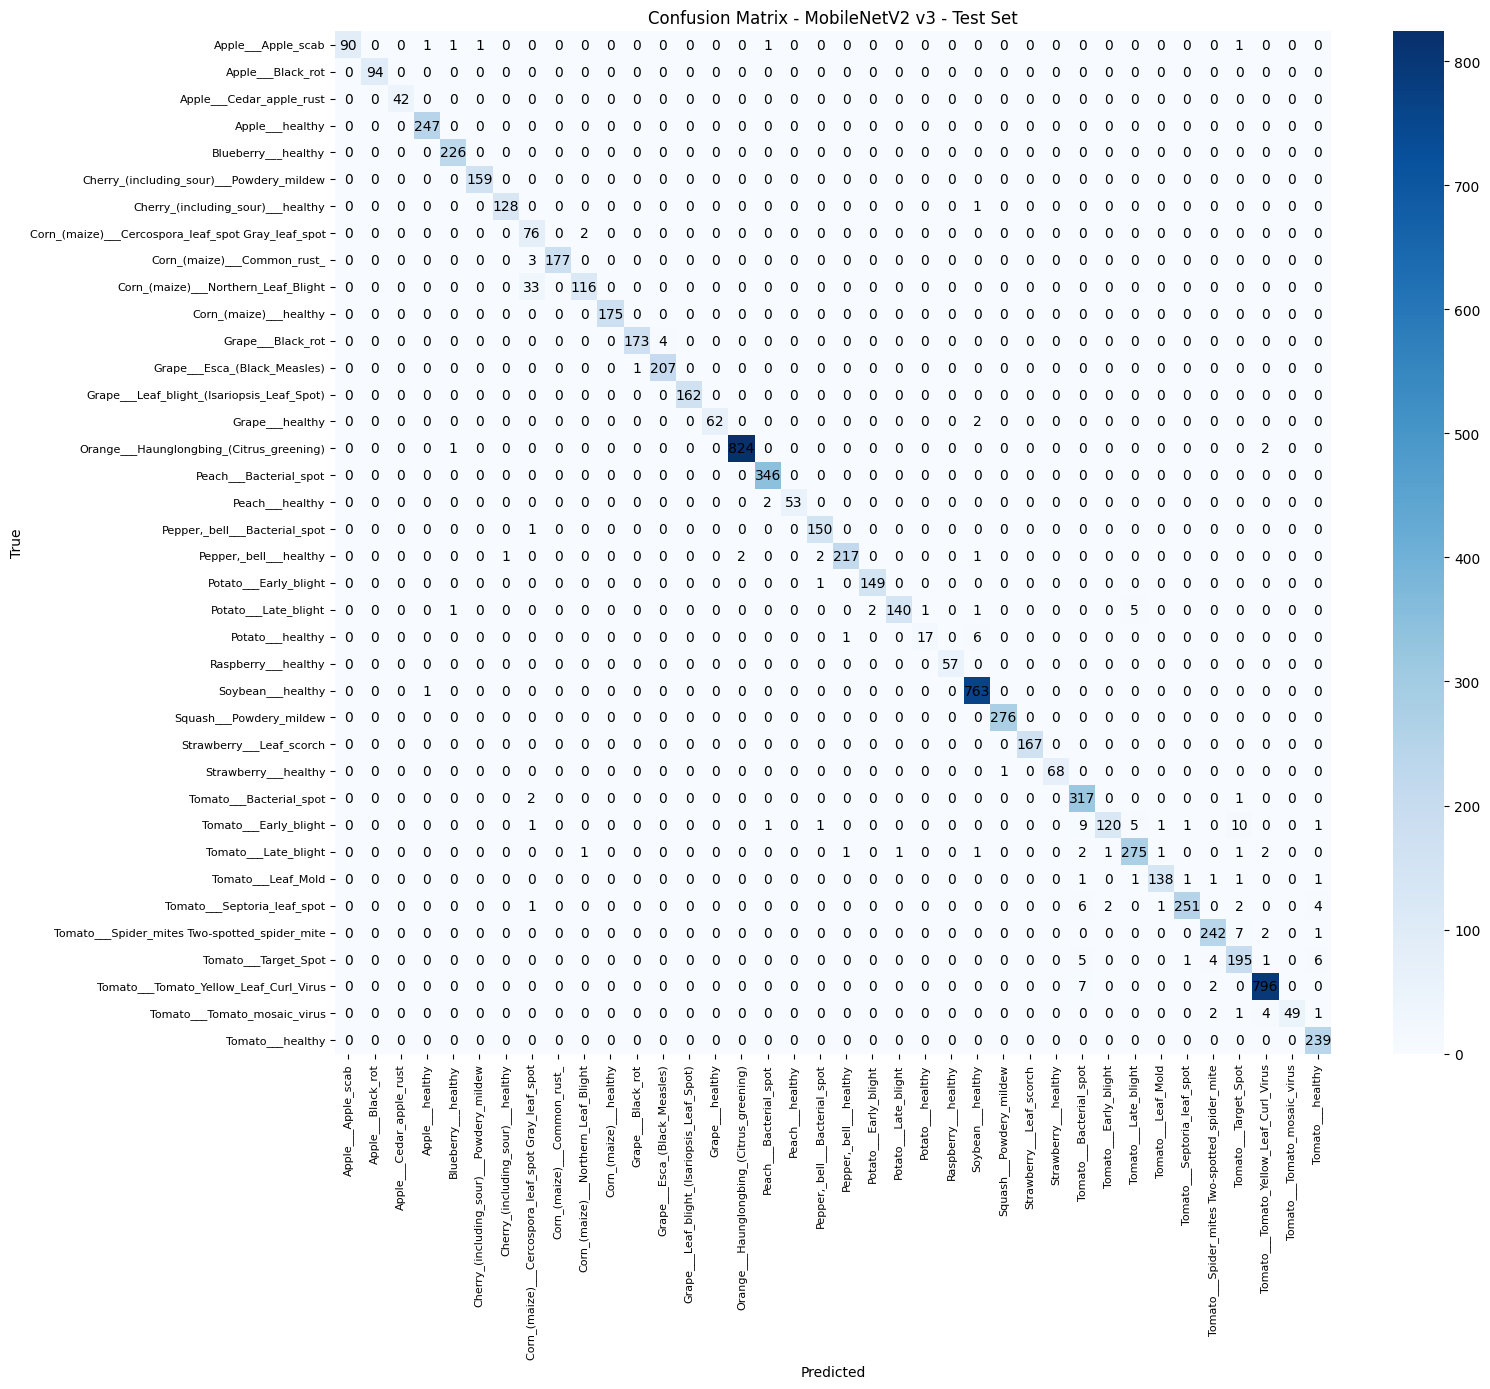

✅ Confusion matrix saved.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(16, 14))

sns.heatmap(
    cm,
    annot=True,              # Show numbers inside cells
    fmt='d',                 # Display as integers
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    annot_kws={"color": "black"}  # Numbers in black
)

plt.title(
    "Confusion Matrix - MobileNetV2 v3 - Test Set"
)

plt.xlabel("Predicted")
plt.ylabel("True")

plt.xticks(
    rotation=90,
    fontsize=8
)

plt.yticks(
    rotation=0,
    fontsize=8
)

plt.tight_layout()

plt.savefig(
    "/content/confusion_matrix_v3.png",
    dpi=150
)

plt.show()

plt.close()

print("✅ Confusion matrix saved.")

In [ ]:
import shutil
import os

EVAL_DIR = "/content/drive/MyDrive/plant_disease_evaluation_v3"

os.makedirs(EVAL_DIR, exist_ok=True)

shutil.copy(
    "/content/confusion_matrix_v3.png",
    EVAL_DIR
)

print("✅ Confusion matrix copied to Google Drive.")
print("Location:")
print(EVAL_DIR + "/confusion_matrix_v3.png")

✅ Confusion matrix copied to Google Drive.
Location:
/content/drive/MyDrive/plant_disease_evaluation_v3/confusion_matrix_v3.png


In [ ]:
import os
import shutil

EVAL_DIR = "/content/drive/MyDrive/plant_disease_evaluation_v3"

os.makedirs(EVAL_DIR, exist_ok=True)

shutil.copy(
    "/content/classification_report_v3.txt",
    EVAL_DIR
)

print("✅ Classification report copied to Google Drive.")
print(
    EVAL_DIR +
    "/classification_report_v3.txt"
)

✅ Classification report copied to Google Drive.
/content/drive/MyDrive/plant_disease_evaluation_v3/classification_report_v3.txt


In [ ]:
model.save(
    "/content/drive/MyDrive/"
    "plant_disease_mobilenetv2_v3.keras"
)

print("✅ Final model saved to Google Drive.")

✅ Final model saved to Google Drive.


In [ ]:
import json

summary = {
    "test_accuracy": float(test_acc),
    "test_loss": float(test_loss),
    "num_classes": int(num_classes),
    "test_samples": int(len(y_true))
}

metrics_path = (
    "/content/drive/MyDrive/"
    "plant_disease_metrics_v3.json"
)

with open(metrics_path, "w") as f:
    json.dump(summary, f, indent=2)

print("✅ Final metrics saved to Google Drive.\n")
print(json.dumps(summary, indent=2))

✅ Final metrics saved to Google Drive.

{
  "test_accuracy": 0.9763942956924438,
  "test_loss": 0.07301150262355804,
  "num_classes": 38,
  "test_samples": 8176
}


In [ ]:
import os
import random

data_dir = "/content/plant_data/cleaned_dataset"

# Get all class folders
class_folders = [
    folder for folder in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, folder))
]

# Pick a random class
actual_class = random.choice(class_folders)

class_path = os.path.join(
    data_dir,
    actual_class
)

# Get image files
image_files = [
    file for file in os.listdir(class_path)
    if file.lower().endswith(
        (".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG")
    )
]

# Pick a random image
image_file = random.choice(image_files)

image_path = os.path.join(
    class_path,
    image_file
)

print("Actual class:", actual_class)
print("Image:", image_file)
print("Path:", image_path)

Actual class: Squash___Powdery_mildew
Image: c64560fe-f2ed-40c6-bdcc-124cfe1cb56f___MD_Powd.M 0583.JPG
Path: /content/plant_data/cleaned_dataset/Squash___Powdery_mildew/c64560fe-f2ed-40c6-bdcc-124cfe1cb56f___MD_Powd.M 0583.JPG


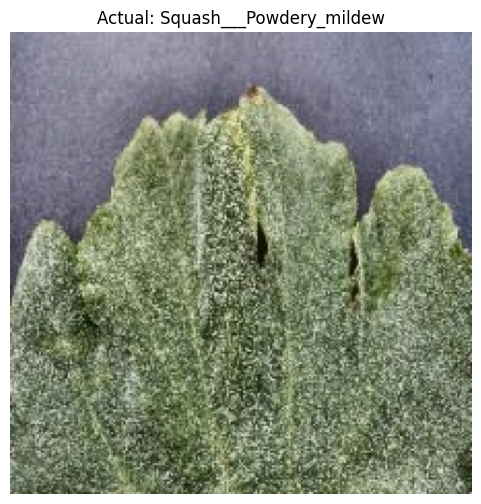

In [ ]:
from tensorflow.keras.utils import load_img
import matplotlib.pyplot as plt

img = load_img(image_path)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(f"Actual: {actual_class}")
plt.show()

In [ ]:
import numpy as np
import tensorflow as tf

img_resized = load_img(
    image_path,
    target_size=(224, 224)
)

img_array = np.array(img_resized)

img_array = tf.keras.applications.mobilenet_v2.preprocess_input(
    img_array
)

img_array = np.expand_dims(
    img_array,
    axis=0
)

print("Image shape:", img_array.shape)

Image shape: (1, 224, 224, 3)


In [ ]:
predictions = model.predict(
    img_array,
    verbose=0
)

predicted_index = np.argmax(
    predictions[0]
)

predicted_class = class_names[
    predicted_index
]

confidence = (
    predictions[0][predicted_index] * 100
)

print("\n" + "=" * 60)
print("PREDICTION RESULT")
print("=" * 60)

print("Actual class:   ", actual_class)
print("Predicted class:", predicted_class)
print(f"Confidence:      {confidence:.2f}%")

print("=" * 60)


PREDICTION RESULT
Actual class:    Squash___Powdery_mildew
Predicted class: Squash___Powdery_mildew
Confidence:      100.00%


In [ ]:
top_3_indices = np.argsort(
    predictions[0]
)[-3:][::-1]

print("\nTop 3 Predictions:")
print("-" * 60)

for rank, index in enumerate(
    top_3_indices,
    start=1
):
    print(
        f"{rank}. "
        f"{class_names[index]} "
        f"→ "
        f"{predictions[0][index] * 100:.2f}%"
    )


Top 3 Predictions:
------------------------------------------------------------
1. Squash___Powdery_mildew → 100.00%
2. Grape___Leaf_blight_(Isariopsis_Leaf_Spot) → 0.00%
3. Tomato___healthy → 0.00%


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.endswith((".keras", ".h5")):
            print(os.path.join(root, file))

/content/drive/MyDrive/plant_disease_mobilenetv2.keras
/content/drive/MyDrive/best_custom_cnn.keras
/content/drive/MyDrive/best_model_stage1.keras
/content/drive/MyDrive/best_model_stage2.keras
/content/drive/MyDrive/plant_disease_mobilenetv2_v2.keras
/content/drive/MyDrive/plant_disease_efficientnetb0_cpu.keras
/content/drive/MyDrive/plant_disease_mobilenetv2_v3.keras
/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage1.keras
/content/drive/MyDrive/plant_checkpoints_v3/best_model_stage2.keras
/content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage1.keras
/content/drive/MyDrive/plant_checkpoints_densenet121/best_model_stage2.keras


In [ ]:
import tensorflow as tf

model_path = "/content/drive/MyDrive/plant_disease_mobilenetv2_v3.keras"

model = tf.keras.models.load_model(model_path)

print("✅ Model loaded successfully")
print("Model:", model.name)

✅ Model loaded successfully
Model: functional_1


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 114 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
print(model.input_shape)
print(model.output_shape)

(None, 224, 224, 3)
(None, 38)


In [ ]:
model.save("/content/drive/MyDrive/model.keras")

print("✅ model.keras created successfully")

✅ model.keras created successfully


In [ ]:
import os

path = "/content/drive/MyDrive/model.keras"

print("Exists:", os.path.exists(path))
print("Size:", os.path.getsize(path) / (1024 * 1024), "MB")

Exists: True
Size: 26.523460388183594 MB


In [ ]:
from google.colab import files

files.download("/content/drive/MyDrive/model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>